# Bottle Gourd Disease Diagnosis: Deep Ensemble Inference and Explainable AI (Minimal Reproduction)

**Paper:** Md. Naimul Islam Nuhash, Md Maruf Kamran Sohag, Shahriar Sultan Ramit, Raja Tariqul Hasan Tusher — *A Deep Ensemble Learning and Explainable AI Framework for Accurate Bottle Gourd Disease Diagnosis and Deployment*.
SSRN preprint DOI [10.2139/ssrn.5398840](https://doi.org/10.2139/ssrn.5398840); journal version DOI [10.1016/j.atech.2025.101541](https://doi.org/10.1016/j.atech.2025.101541) (*Smart Agricultural Technology* 12:101541, CC BY 4.0, 2025-10-17).

**Author code (executed directly, not paraphrased):** [`sohag221/Bottle-Gourd-Disease-Classification`](https://github.com/sohag221/Bottle-Gourd-Disease-Classification) @ commit `be3a8c9e9495eccaf1a8204d8989ddbd2f08e169` — `app.py` (six-backbone ensemble served behind Flask `/predict`) and `cam_visualizer.py` (DenseNet121 Grad-CAM / Grad-CAM++ / EigenCAM / ScoreCAM). This notebook downloads those two pinned files and imports them, so the scientific logic is the authors' own Python.

**Scope — PARTIAL demonstration of the deployed inference path:**
- Load the six released `*_best.pth` checkpoints and run the authors' probability-averaging ensemble on **one** author-provided testing image.
- Exercise the authors' actual Flask `/predict` route via a local test client (no server, no ngrok deployment).
- Generate DenseNet121 CAM explainability overlays with the authors' `cam_visualizer.py`.

**Not covered:** training (none released), the training dataset (not in the repository and its public source is not stated), dataset-level metrics, the Flask/ngrok deployment chrome, and whether the paper's reported ensemble is the plain averaging (deployed `app.py`) or the `stacking_ensemble_model.pkl` meta-learner — the full text was not retrievable (SSRN 403; ScienceDirect blocked); the stacking artifact is inspected diagnostically only.

**Execution status:** this notebook is executed end-to-end on a fresh Google Colab runtime before delivery; the runtime that produced the saved outputs is stated in the results section.

**日本語要約:** このノートブックは、スズメウリ科作物（ヘチマ）病害診断のための6モデル深層アンサンブル推論を、著者自身のピン留めされたコード（`app.py`・`cam_visualizer.py`、コミット `be3a8c9e`）をそのまま実行して再現する最小デモです。著者提供のテスト画像1枚に対し、リリース済み6つのチェックポイントでアンサンブル推論とDenseNet121のCAM可視化を行います。学習・データセット全体の評価・Web配備は対象外です。

## 1. Runtime selection

This notebook runs on **either** a standard **CPU** runtime or a **T4 GPU** runtime; the authors' own code selects `cuda` only when available (`app.py`: `DEVICE = torch.device('cuda' if torch.cuda.is_available() else 'cpu')`). Recommended: **T4 GPU** for faster ScoreCAM, but CPU completes the same analysis on the single image. Select the runtime via *ランタイム → ランタイムの変更*, then **Run all**.

Expected: ≈500 MB of downloads (six checkpoints + two small artifacts + one sample image) and ≈5–15 min end-to-end on T4 (ScoreCAM dominates; longer on CPU).

**日本語:** CPU でも T4 GPU でも動作します（推奨は T4）。ダウンロード約 500 MB、T4 で全体 5〜15 分程度、ScoreCAM が大半を占めます。

**AI glue notice:** The scientific code is the authors' pinned `app.py` and `cam_visualizer.py`, executed directly. Notebook glue cells (download verification, plotting, CSV export, the stacking diagnostic) are AI-generated and are labeled as such; they do not alter the authors' computations.

In [ ]:
# Report the environment and select the device exactly as the authors' app.py does.
import platform
import torch
import torchvision

print("Python:", platform.python_version())
print("torch:", torch.__version__, "| torchvision:", torchvision.__version__)
DEVICE = torch.device("cuda" if torch.cuda.is_available() else "cpu")  # author app.py:20 logic
print("DEVICE (author app.py logic):", DEVICE)
if DEVICE.type == "cuda":
    print("GPU:", torch.cuda.get_device_name(0))

Python: 3.13.16
torch: 2.11.0+cpu | torchvision: 0.26.0+cpu
DEVICE (author app.py logic): cpu


## 2. Dependencies

Colab already ships torch/torchvision, Flask, numpy, Pillow, scikit-learn, joblib, OpenCV and matplotlib. The authors' `requirements.txt` lists `torch`, `torchvision`, `timm`, `Pillow`, `numpy`, `scikit-learn`, `joblib` but omits the CAM library used by their `cam_visualizer.py`: `cam_visualizer.py` imports `pytorch_grad_cam`, whose PyPI **distribution** is named `grad-cam` (the import name is unchanged; `pip install pytorch-grad-cam` does not exist on PyPI). We install **timm** and **grad-cam** here.

**日本語:** Colab に大部分は同梱済みのため、`timm` と、`cam_visualizer.py` が必要とする CAM ライブラリのみ追加でインストールします。PyPI の配布名は `grad-cam`（import 名は `pytorch_grad_cam` のまま）です。

In [ ]:
%pip install -q timm grad-cam

  Installing build dependencies ... done


  Getting requirements to build wheel ... done


  Preparing metadata (pyproject.toml) ... done


Verify that every module the authors' pinned code imports is actually available before downloading anything.

**日本語:** ダウンロードの前に、著者コードが必要とする全モジュールが実際に利用可能か確認します。

In [ ]:
# Verify every import the authors' modules need is actually importable in this runtime.
import timm, pytorch_grad_cam, flask, sklearn, joblib, cv2, numpy, PIL, matplotlib
print("timm:", timm.__version__)
print("pytorch-grad-cam:", pytorch_grad_cam.__version__ if hasattr(pytorch_grad_cam, "__version__") else "installed")
print("flask:", flask.__version__)
print("numpy:", numpy.__version__, "| Pillow:", PIL.__version__, "| OpenCV:", cv2.__version__)

timm: 1.0.30
pytorch-grad-cam: installed
flask: 3.1.3
numpy: 2.1.3 | Pillow: 11.3.0 | OpenCV: 5.0.0


/tmp/ipykernel_1205/2939515809.py:5: DeprecationWarning: The '__version__' attribute is deprecated and will be removed in Flask 3.2. Use feature detection or 'importlib.metadata.version("flask")' instead.
  print("flask:", flask.__version__)


## 3. Inputs and weights — provenance and verified download

All model/sample bytes are downloaded **inside this Colab runtime** from the authors' pinned commit `be3a8c9e9495eccaf1a8204d8989ddbd2f08e169`:

- The six `*_best.pth` files are **Git LFS** objects, so they are fetched via `media.githubusercontent.com` (the LFS media route) and verified against the SHA-256 OIDs and byte sizes recorded in the repository's LFS pointer blobs (metadata only; no weight bytes were ever inspected on the authoring host).
- `label_encoder.pkl`, `stacking_ensemble_model.pkl`, `app.py`, `cam_visualizer.py`, and the sample image `testing_images/photo_2025-10-13_06-27-24.jpg` are regular git blobs fetched from `raw.githubusercontent.com` and verified by git blob SHA-1 (`sha1(b"blob <len>\0" + bytes)`).

The sample image is the smallest file in the authors' `testing_images/` directory (88,556 bytes) — a deterministic, author-provided input.

**日本語:** 重み6点は Git LFS オブジェクトのため `media.githubusercontent.com` から取得し、LFSポインタに記録された SHA-256 とサイズで検証します。その他の小ファイルとサンプル画像は raw URL から取得し git blob SHA-1 で検証します。

In [ ]:
import hashlib
import urllib.request
from pathlib import Path

WORK = Path("/content/bottle_gourd_ensemble")
WORK.mkdir(parents=True, exist_ok=True)
COMMIT = "be3a8c9e9495eccaf1a8204d8989ddbd2f08e169"
MEDIA = f"https://media.githubusercontent.com/media/sohag221/Bottle-Gourd-Disease-Classification/{COMMIT}"

# name -> (LFS oid sha256, declared byte size) — recorded from the repository's LFS pointer blobs
CHECKPOINTS = {
    "resnet50_best.pth":       ("62e164858ae329570288690cf8808b7a15dc0957a7964c4418705d1a7183c5ba", 94_411_530),
    "efficientnetb3_best.pth": ("cc25e8509c538b938bd61574e6fda2978aa1a9f4ad3cc586b9bdb2903f3e5450", 43_383_694),
    "densenet121_best.pth":    ("cf7d7d7c53052ac2b909f1a67bb3d9c6a36e633dd76dea1e04f084fb384693ca", 28_464_055),
    "inceptionv3_best.pth":    ("ed5715ab1f10d6e4c1bdc5c7fd72d663398eedd47f11009f34a152b12aff3459", 87_548_496),
    "convnext_best.pth":       ("d13f3c2bd309fbdbdcfa5168bd56a8de92dafd9b72e86bf4712c8f7ca6cc2442", 111_372_962),
    "swin_tiny_best.pth":      ("0156665ddf212723219fc6842b3abcec35588564b0c0e124aedcccca500b5248", 110_167_279),
}

for name, (oid, size) in CHECKPOINTS.items():
    dest = WORK / name
    if not dest.exists() or dest.stat().st_size != size:
        print(f"downloading {name} ({size:,} bytes) ...", flush=True)
        urllib.request.urlretrieve(f"{MEDIA}/{name}", dest)
    data = dest.read_bytes()
    assert not data.lstrip().startswith(b"version https://git-lfs"), f"LFS pointer not resolved: {name}"
    assert len(data) == size, f"{name}: size {len(data):,} != {size:,}"
    assert hashlib.sha256(data).hexdigest() == oid, f"{name}: sha256 mismatch"
    print(f"OK {name}: {len(data):,} bytes, sha256 verified")

downloading resnet50_best.pth (94,411,530 bytes) ...


OK resnet50_best.pth: 94,411,530 bytes, sha256 verified
downloading efficientnetb3_best.pth (43,383,694 bytes) ...


OK efficientnetb3_best.pth: 43,383,694 bytes, sha256 verified
downloading densenet121_best.pth (28,464,055 bytes) ...


OK densenet121_best.pth: 28,464,055 bytes, sha256 verified
downloading inceptionv3_best.pth (87,548,496 bytes) ...


OK inceptionv3_best.pth: 87,548,496 bytes, sha256 verified
downloading convnext_best.pth (111,372,962 bytes) ...


OK convnext_best.pth: 111,372,962 bytes, sha256 verified
downloading swin_tiny_best.pth (110,167,279 bytes) ...


OK swin_tiny_best.pth: 110,167,279 bytes, sha256 verified


Small artifacts (label encoder, stacking pickle), the two pinned author modules, and the sample image are regular git blobs: fetched from `raw.githubusercontent.com` and verified by git blob SHA-1 before use.

**日本語:** 小型ファイル・著者の2モジュール・サンプル画像は通常の git blob として取得し、git blob SHA-1 で検証します。

In [ ]:
# Small artifacts, the two pinned author modules, and the sample image (regular git blobs).
RAW = f"https://raw.githubusercontent.com/sohag221/Bottle-Gourd-Disease-Classification/{COMMIT}"
GIT_BLOBS = {  # relative path -> expected git blob SHA-1
    "label_encoder.pkl": "28ed593c8e3283d849229f91834fefc62c2a1f5a",
    "stacking_ensemble_model.pkl": "2b690a48f0547b33cb04e081461114a00bf29b83",
    "app.py": "0ee22f9b8849a398d752612728943efa5ce4b597",
    "cam_visualizer.py": "fae1c70f995256a9d43c4b70542cec186fb1a57e",
    "testing_images/photo_2025-10-13_06-27-24.jpg": "1bfc430cf10e36d8c47ca6eef5fa7108057d040f",
}

def git_blob_sha1(data: bytes) -> str:
    return hashlib.sha1(b"blob %d\x00" % len(data) + data).hexdigest()

for rel, sha in GIT_BLOBS.items():
    dest = WORK / rel
    dest.parent.mkdir(parents=True, exist_ok=True)
    if not dest.exists():
        urllib.request.urlretrieve(f"{RAW}/{rel}", dest)
    data = dest.read_bytes()
    assert git_blob_sha1(data) == sha, f"{rel}: git blob SHA-1 mismatch"
    print(f"OK {rel}: {len(data):,} bytes, blob sha verified")

SAMPLE = WORK / "testing_images" / "photo_2025-10-13_06-27-24.jpg"
print("Sample input:", SAMPLE)

OK label_encoder.pkl: 383 bytes, blob sha verified
OK stacking_ensemble_model.pkl: 3,311 bytes, blob sha verified


OK app.py: 12,728 bytes, blob sha verified
OK cam_visualizer.py: 14,097 bytes, blob sha verified


OK testing_images/photo_2025-10-13_06-27-24.jpg: 88,556 bytes, blob sha verified
Sample input: /content/bottle_gourd_ensemble/testing_images/photo_2025-10-13_06-27-24.jpg


### Input preview

The authors' testing image, shown exactly as downloaded (no preprocessing). Its dimensions and mode are printed from the actual bytes. This is the single minimal input used for the whole demonstration.

**日本語:** 著者提供のテスト画像をそのまま表示します（前処理前）。本デモで使う入力はこの1枚のみです。

Sample: photo_2025-10-13_06-27-24.jpg | size (W×H): (1024, 1024) | mode: RGB


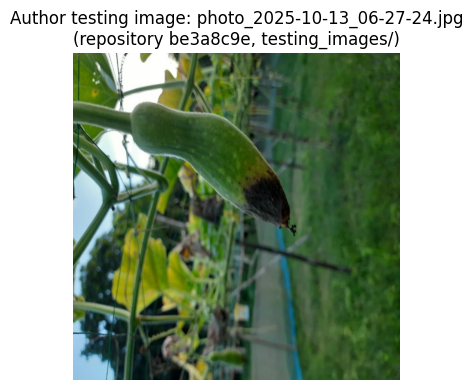

In [ ]:
import matplotlib.pyplot as plt
from PIL import Image

img = Image.open(SAMPLE).convert("RGB")
print("Sample:", SAMPLE.name, "| size (W×H):", img.size, "| mode:", img.mode)

fig, ax = plt.subplots(figsize=(4, 4))
ax.imshow(img)
ax.set_title(f"Author testing image: {SAMPLE.name}\n(repository be3a8c9e, testing_images/)")
ax.axis("off")
plt.tight_layout()
plt.savefig("/content/input_preview.png", dpi=110, bbox_inches="tight")
plt.show()

## 4. Load the authors' inference module

`app.py` defines the six timm backbones (`resnet50`, `efficientnet_b3`, `densenet121`, `inception_v3`, `convnext_tiny`, `swin_tiny_patch4_window7_224`, all `pretrained=False`, `num_classes=7`), the preprocessing (`Resize((224,224)) → ToTensor → ImageNet normalize`), and the probability-averaging `ensemble_predict`. Importing it executes the authors' own model-loading loop from the working directory that now contains the verified checkpoints — exactly what happens when the authors start their Flask server.

**日本語:** 著者の `app.py` をインポートします。モジュール読み込み時に、検証済みチェックポイントから6モデルが著者自身の読み込みコードでロードされます（Flask サーバ起動時と同じ経路）。

In [ ]:
import os
import sys

os.chdir(WORK)  # author app.py loads checkpoints/label_encoder.pkl from the CWD
if str(WORK) not in sys.path:
    sys.path.insert(0, str(WORK))
import app as author_app  # noqa: E402 — author module; prints its own loading progress

print("Models loaded by author code:", list(author_app.models.keys()))
print("Label encoder classes (author label_encoder.pkl):", list(author_app.label_encoder.classes_))

🔧 Using device: cpu
🚀 Loading PyTorch models...


✅ Loaded resnet50


✅ Loaded efficientnetb3


✅ Loaded densenet121


✅ Loaded inceptionv3


✅ Loaded convnext


✅ Loaded swin_tiny
✅ Label encoder loaded: [0 1 2 3 4 5 6]
📊 Total models loaded: 6
🎯 Disease classes: 7
Models loaded by author code: ['resnet50', 'efficientnetb3', 'densenet121', 'inceptionv3', 'convnext', 'swin_tiny']
Label encoder classes (author label_encoder.pkl): [np.int64(0), np.int64(1), np.int64(2), np.int64(3), np.int64(4), np.int64(5), np.int64(6)]


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LabelEncoder from version 1.2.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 5. Ensemble inference on the sample — via the authors' actual `/predict` route

Instead of re-implementing the ensemble, we POST the sample image to the authors' Flask app with a local **test client**, exercising the exact `/predict` handler: preprocess → six forward passes (softmax) → probability averaging → argmax. The JSON response fields (`prediction`, `confidence`, `all_predictions`, `individual_models`, `inference_time_s`) are the authors' own output contract.

**日本語:** アンサンブルを再実装せず、著者の Flask `/predict` をローカルのテストクライアントで呼び出します。レスポンスは著者コード本来の JSON 形式です。

In [ ]:
import pandas as pd

client = author_app.app.test_client()
with open(SAMPLE, "rb") as fh:
    resp = client.post("/predict", data={"image": (fh, SAMPLE.name)},
                       content_type="multipart/form-data")
print("HTTP status:", resp.status_code)
result = resp.get_json()
assert result is not None and result.get("status") == "success", result

print("Ensemble prediction:", result["prediction"], "| confidence:", result["confidence"])
print("Inference time (preprocess + models, reported by author route):", result["inference_time_s"], "s")

per_model = pd.DataFrame(result["individual_models"]).T
per_model = per_model[["prediction", "confidence"]]
display(per_model)

🖼️ Processing image: photo_2025-10-13_06-27-24.jpg
📏 Image size: (1024, 1024)
🔢 Tensor shape: torch.Size([1, 3, 224, 224])


🔍 resnet50: Class 2 (98.70%)
🔍 efficientnetb3: Class 3 (99.96%)


🔍 densenet121: Class 2 (96.00%)
🔍 inceptionv3: Class 2 (99.43%)


🔍 convnext: Class 3 (61.39%)


🔍 swin_tiny: Class 0 (99.81%)
⏱️ Inference time (preprocess+models): 2.5026s
🎯 Ensemble Prediction: Blossom end rot (55.11%)
HTTP status: 200
Ensemble prediction: Blossom end rot | confidence: 55.11%
Inference time (preprocess + models, reported by author route): 2.502604587999997 s


,prediction,confidence
convnext,3,61.39%
densenet121,2,96.00%
efficientnetb3,3,99.96%
inceptionv3,2,99.43%
resnet50,2,98.70%
swin_tiny,0,99.81%


### Ensemble class probabilities

The averaged probability distribution over the seven disease classes (`all_predictions` from the authors' response), plotted as an additional visualization created for this notebook — the paper's figures were not reproducible from the available material. A CSV export is written inside Colab next to the outputs.

**日本語:** アンサンブル後の7クラス確率を棒グラフで表示します（このノートブックで追加作成した図であり、論文の図ではありません）。CSV も Colab 内に保存します。

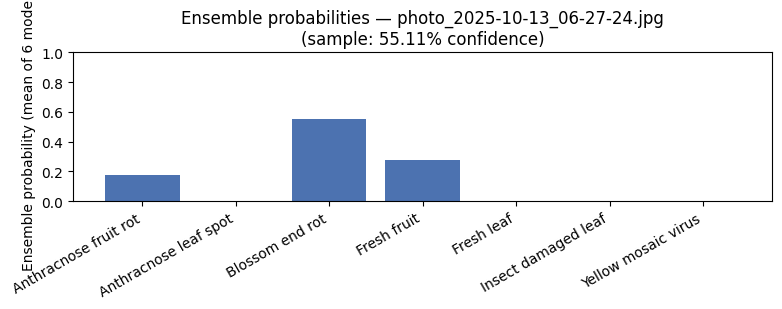

,class,ensemble_probability
0,Anthracnose fruit rot,0.1733
1,Anthracnose leaf spot,0.0001
2,Blossom end rot,0.5511
3,Fresh fruit,0.2743
4,Fresh leaf,0.0002
5,Insect damaged leaf,0.0001
6,Yellow mosaic virus,0.0009


In [ ]:
probs = {k: float(v.rstrip("%")) / 100.0 for k, v in result["all_predictions"].items()}
probs_df = pd.DataFrame({"class": list(probs), "ensemble_probability": list(probs.values())})
probs_df.to_csv("/content/ensemble_probabilities.csv", index=False)

fig, ax = plt.subplots(figsize=(8, 3.2))
ax.bar(probs_df["class"], probs_df["ensemble_probability"], color="#4C72B0")
ax.set_ylabel("Ensemble probability (mean of 6 models)")
ax.set_title(f"Ensemble probabilities — {SAMPLE.name}\n(sample: {result['confidence']} confidence)")
ax.set_ylim(0, 1)
plt.xticks(rotation=30, ha="right")
plt.tight_layout()
plt.savefig("/content/ensemble_probabilities.png", dpi=120, bbox_inches="tight")
plt.show()
display(probs_df)

## 6. Explainability — DenseNet121 CAM overlays (authors' `cam_visualizer.py`)

The authors' CAM tool targets `model.features.denseblock4.denselayer16.conv2` of DenseNet121 and offers Grad-CAM, Grad-CAM++, EigenCAM and ScoreCAM (paper discusses Grad-CAM-family explainability; which backbones the paper's XAI figures cover is unverifiable from the available material — the repository implements DenseNet121 only). We instantiate the authors' visualizer on the loaded DenseNet121 and generate all four methods for DenseNet121's own predicted class.

**Documented AI-generated repair:** the pinned authors' `generate_cam_visualization` (cam_visualizer.py lines 143–144) wraps the CAM call in `torch.no_grad()`, under which pytorch-grad-cam cannot backpropagate — every method fails with `RuntimeError: element 0 of tensors does not require grad...` (observed on this runtime with the unmodified pinned file). The cell below therefore uses the authors' own visualizer objects, preprocessing, target class logic and `show_cam_on_image` usage, but performs the CAM call in a gradient-enabled context — the only change; nothing else is altered. ScoreCAM runs extra forward passes and is the slowest step; on CPU allow a few minutes.

**日本語:** 著者の `cam_visualizer.py`（DenseNet121 専用）で Grad-CAM / Grad-CAM++ / EigenCAM / ScoreCAM を生成します。ピン留めされた著者コードは CAM 呼び出しを `torch.no_grad()` で包んでおり、このままでは逆伝播できず全手法が失敗するため（本ランタイムで確認）、CAM 呼び出しのみ勾配が有効な文脈で実行します。それ以外の計算は著者コードのままです。

In [ ]:
from cam_visualizer import create_densenet_cam_visualizer  # author module
import numpy as np
import torch
from pytorch_grad_cam.utils.image import show_cam_on_image
from pytorch_grad_cam.utils.model_targets import ClassifierOutputTarget

densenet = author_app.models["densenet121"]
device = next(densenet.parameters()).device
visualizer = create_densenet_cam_visualizer(densenet, device)  # author init: target layer denseblock4.denselayer16.conv2

pil_input = Image.open(SAMPLE).convert("RGB")
input_tensor, rgb_img = visualizer.preprocess_image_for_cam(pil_input)  # author preprocessing (224x224, ImageNet norm)

# Target class = DenseNet121's own prediction (the authors' generate_all_cam_visualizations logic).
with torch.no_grad():
    target_class = int(densenet(input_tensor).argmax(dim=1).item())
print("DenseNet121 target class:", target_class, "=", author_app.disease_class_names[target_class])

# AI-generated repair (see markdown above): authors' CAM objects + preprocessing + show_cam_on_image,
# executed in a gradient-enabled context instead of the authors' no_grad wrapper.
cam_overlays = {}
for method_name, cam_object in visualizer.cam_methods.items():
    grayscale_cam = cam_object(input_tensor=input_tensor, targets=[ClassifierOutputTarget(target_class)])[0, :]
    grayscale_cam = np.clip(grayscale_cam.astype(np.float32), 0, 1)
    cam_overlays[method_name] = Image.fromarray(show_cam_on_image(rgb_img, grayscale_cam, use_rgb=True))
    print(f"{method_name}: OK, max activation {grayscale_cam.max():.3f}")

✅ Grad-CAM initialized
✅ Grad-CAM++ initialized
✅ EigenCAM initialized
✅ ScoreCAM initialized


DenseNet121 target class: 2 = Blossom end rot


gradcam: OK, max activation 1.000


gradcam++: OK, max activation 1.000


eigencam: OK, max activation 1.000


  0%|          | 0/2 [00:00<?, ?it/s]

 50%|█████     | 1/2 [00:21<00:21, 21.56s/it]

100%|██████████| 2/2 [00:43<00:00, 21.54s/it]

100%|██████████| 2/2 [00:43<00:00, 21.55s/it]

scorecam: OK, max activation 1.000


### Input versus Grad-CAM overlay

The original testing image beside the Grad-CAM overlay produced by the authors' code. The heatmap is a **model prediction artifact** (not a reference annotation): warm regions are where DenseNet121 concentrates evidence for its predicted class.

**日本語:** 元画像と、著者コードが生成した Grad-CAM の重ね合わせ。ヒートマップはモデル予測に基づくものであり、参照アノテーションではありません。

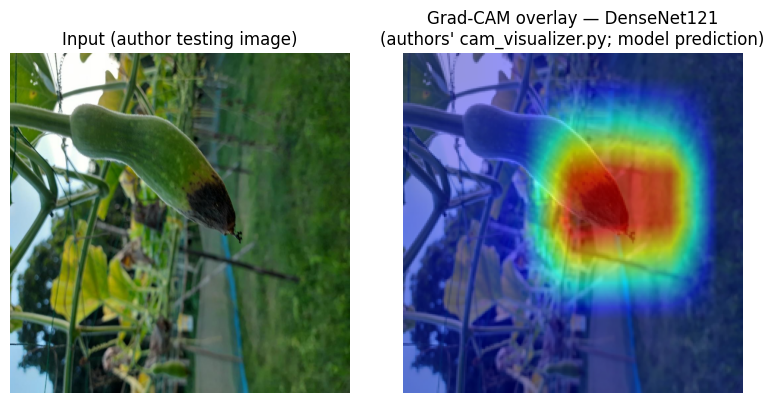

In [ ]:
fig, axes = plt.subplots(1, 2, figsize=(8, 4))
axes[0].imshow(pil_input)
axes[0].set_title("Input (author testing image)")
axes[1].imshow(cam_overlays["gradcam"])
axes[1].set_title("Grad-CAM overlay — DenseNet121\n(authors' cam_visualizer.py; model prediction)")
for ax in axes:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/input_vs_gradcam.png", dpi=120, bbox_inches="tight")
plt.show()

### All four CAM methods

Comparison grid of the four methods generated by the authors' visualizer for the same input and target class.

**日本語:** 同じ入力・同じ対象クラスに対する4手法の比較グリッド。

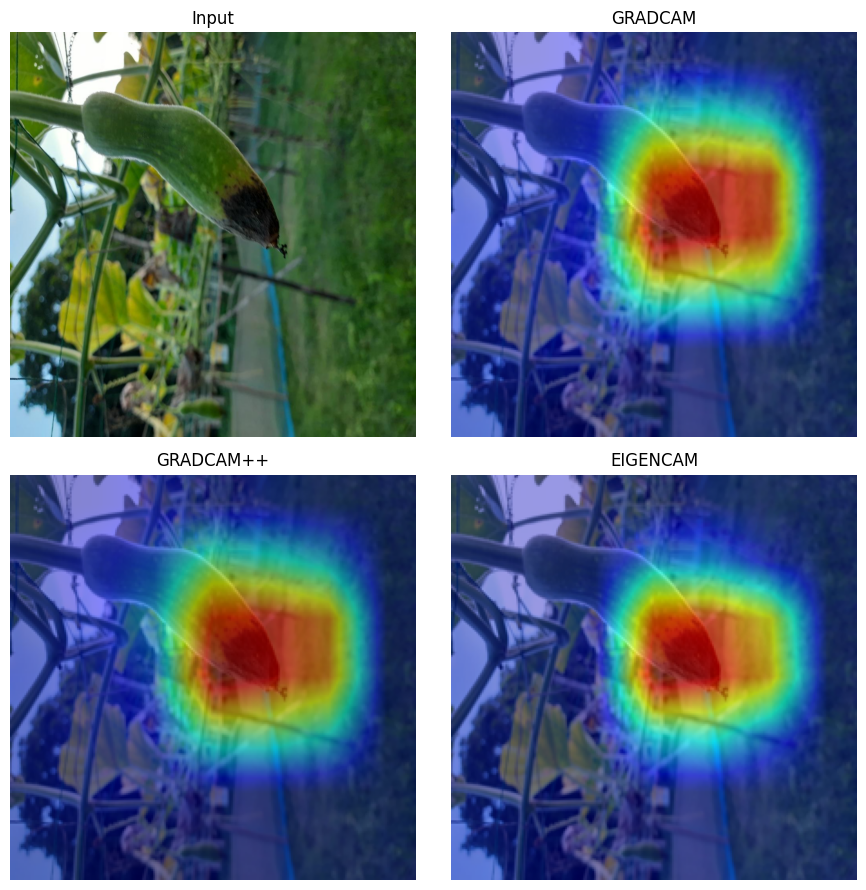

In [ ]:
methods = ["gradcam", "gradcam++", "eigencam", "scorecam"]
fig, axes = plt.subplots(2, 2, figsize=(9, 9))
axes[0, 0].imshow(pil_input)
axes[0, 0].set_title("Input")
for ax, m in zip(axes.flat[1:], methods):
    ax.imshow(cam_overlays[m])
    ax.set_title(m.upper())
for ax in axes.flat:
    ax.axis("off")
plt.tight_layout()
plt.savefig("/content/cam_comparison.png", dpi=120, bbox_inches="tight")
plt.show()

## 7. Diagnostic: `stacking_ensemble_model.pkl` contract

The repository also ships a 3.3 KB `stacking_ensemble_model.pkl`, but the deployed `app.py` uses plain probability averaging and never loads it; whether the paper's reported ensemble is averaging or stacking is unverifiable without the article text. This AI-generated diagnostic cell inspects the artifact's learned contract only (`n_features_in_`, classes) and, **if and only if** it expects exactly the six per-model probabilities, compares its prediction with the averaging result. Any other contract is reported and left unresolved — no substitute computation is invented.

**日本語:** リポジトリには `stacking_ensemble_model.pkl` も同梱されていますが、デプロイ済み `app.py` は確率平均のみを使用します。この診断セルは成果物の契約（特徴数・クラス）を確認し、6モデルの確率ベクトルを期待する場合に限って比較します。それ以外の契約は解決せずに報告します。

In [ ]:
import joblib
import numpy as np

stacking_model = joblib.load(WORK / "stacking_ensemble_model.pkl")
print("Type:", type(stacking_model).__name__)
n_features = getattr(stacking_model, "n_features_in_", None)
print("n_features_in_:", n_features)
classes = getattr(stacking_model, "classes_", None)
print("classes_:", classes)

if n_features == 6:
    model_probs = np.stack([np.asarray(v["probabilities"]) for v in result["individual_models"].values()])
    stacking_probs = stacking_model.predict_proba(model_probs)[0]
    stack_df = pd.DataFrame({"class": author_app.disease_class_names,
                             "averaging": [probs[c] for c in author_app.disease_class_names],
                             "stacking": stacking_probs})
    display(stack_df)
    print("averaging argmax:", author_app.disease_class_names[int(np.argmax(model_probs.mean(axis=0)))])
    print("stacking argmax: ", author_app.disease_class_names[int(np.argmax(stacking_probs))])
else:
    print("Contract does not match the six per-model probabilities; leaving unresolved (no substitute computed).")

Type: LogisticRegression
n_features_in_: 42
classes_: [0 1 2 3 4 5 6]
Contract does not match the six per-model probabilities; leaving unresolved (no substitute computed).


/usr/local/lib/python3.13/dist-packages/sklearn/base.py:380: InconsistentVersionWarning: Trying to unpickle estimator LogisticRegression from version 1.2.2 when using version 1.6.1. This might lead to breaking code or invalid results. Use at your own risk. For more info please refer to:
https://scikit-learn.org/stable/model_persistence.html#security-maintainability-limitations
  warnings.warn(


## 8. Interpretation and limitations

- **What was reproduced:** the authors' deployed inference path — six released checkpoints, their preprocessing, and their probability-averaging ensemble — executed through their own `/predict` handler on one author-provided testing image, plus DenseNet121 Grad-CAM/Grad-CAM++/EigenCAM/ScoreCAM from their own visualizer objects. Two documented adaptations were required: the CAM library must be installed as the PyPI distribution `grad-cam` (import name `pytorch_grad_cam`; the authors' requirements omit it), and the CAM call must run in a gradient-enabled context because the pinned authors' wrapper uses `torch.no_grad()` around it (see §6); no other author computation was altered.
- **What this does not show:** dataset-level accuracy or any paper metric (the article text was not retrievable: SSRN HTTP 403, ScienceDirect blocked, no OpenAlex cached copy for either version); the averaging-vs-stacking question is left open unless the §7 diagnostic resolved it; no reference annotations exist for the sample, so prediction correctness is not verified — only that the released artifacts behave as the authors' code defines.
- **Provenance:** all inputs came from the pinned commit `be3a8c9e…` with byte-level verification (SHA-256 for LFS weights, git blob SHA-1 for the rest) inside this runtime.
- **日本語:** 再現したのは著者デプロイ済み推論経路（6チェックポイント・確率平均・CAM）の最小例です。データセット精度や論文の指標は検証していません（本文が取得不能のため）。サンプルには参照アノテーションがないため、予測の正誤は確認できません。

**References:** SSRN 10.2139/ssrn.5398840 (preprint); Smart Agricultural Technology 12:101541 (journal version, CC BY 4.0); repository commit `be3a8c9e9495eccaf1a8204d8989ddbd2f08e169` (files `app.py`, `cam_visualizer.py`, `README.md`, `PROJECT_DOCUMENTATION.md`); PhenoPaper investigation `p-dad8cfbd3c93f02b7df2cc2ab9484639-20261006T222405Z-3395728` used as prior research guidance only.